# PIN Tunja — Adquisición y procesamiento de datos
**Proyecto Integrador · Ingeniería de Datos e IA · Universidad Santo Tomás, Seccional Tunja · 2026-2**
Camilo Arias · Nataly Sofía Forero Aparicio · Alan Duwa Galvis

Este cuaderno contiene el código de las dos cadenas de datos del proyecto:

1. **Web scraping de precios de repuestos** (ETL): extracción en Falabella y Éxito, transformación (limpieza, filtro de relevancia, atípicos con IQR, merge sort, mediana) y carga a CSV/JSON.
2. **Procesamiento de la señal del acelerómetro** (ESP32 + MPU6050): quitar gravedad, ventanas de 1 s con 50 % de traslape, medidas por ventana y clasificador por umbrales.

Archivo de datos que acompaña al cuaderno: `scraping_precios_amortiguador_delantero.csv`.

In [1]:
import re, json, math, unicodedata, os
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EN_VIVO = False   # True = descargar de las tiendas ahora; False = usar el CSV guardado
CONSULTA = "amortiguador delantero"
ARCHIVO = "scraping_precios_amortiguador_delantero.csv"

## 1. Extracción (web scraping)
Tres tiendas, tres técnicas:

| Tienda | Técnica |
|---|---|
| Falabella | Se descarga la página de resultados y se lee el JSON incrustado en `<script id="__NEXT_DATA__">` |
| Éxito | API pública en JSON de la plataforma VTEX |
| MercadoLibre | HTML + expresiones regulares; si la tienda pide iniciar sesión, **se informa y no se evade** |

Entre tiendas se deja una pausa para no cargar los sitios.

In [2]:
import time
try:
    import requests
except ImportError:
    requests = None

CABECERAS = {"User-Agent": "Mozilla/5.0 (PIN Tunja, proyecto academico USTA)"}

def falabella(consulta):
    url = "https://www.falabella.com.co/falabella-co/search?Ntt=" + consulta.replace(" ", "+")
    html = requests.get(url, headers=CABECERAS, timeout=20).text
    bloque = re.search(r'<script id="__NEXT_DATA__"[^>]*>(.*?)</script>', html, re.S).group(1)
    datos = json.loads(bloque)
    filas = []
    for p in datos["props"]["pageProps"].get("results", []):
        precios = [x for x in p.get("prices", []) if not x.get("crossed")]   # se ignora el precio tachado
        if not precios: continue
        valor = int(str(precios[0]["price"][0]).replace(".", ""))
        filas.append(dict(tienda="Falabella", tecnica="HTML -> JSON incrustado (__NEXT_DATA__)",
                          nombre=p.get("displayName"), precio_cop=valor,
                          vendedor=p.get("sellerName"), disponible=1, url=p.get("url")))
    return filas

def exito(consulta):
    url = "https://www.exito.com/api/catalog_system/pub/products/search?ft=" + consulta + "&_from=0&_to=49"
    filas = []
    for p in requests.get(url, headers=CABECERAS, timeout=20).json():
        oferta = p["items"][0]["sellers"][0]["commertialOffer"]
        filas.append(dict(tienda="Exito", tecnica="API publica JSON (VTEX)", nombre=p["productName"],
                          precio_cop=int(oferta["Price"]), vendedor=p["items"][0]["sellers"][0]["sellerName"],
                          disponible=int(oferta["AvailableQuantity"] > 0), url=p["link"]))
    return filas

def mercadolibre(consulta):
    url = "https://listado.mercadolibre.com.co/" + consulta.replace(" ", "-")
    r = requests.get(url, headers=CABECERAS, timeout=20)
    if "login" in r.url or "account-verification" in r.text:
        print("MercadoLibre pidió iniciar sesión: se informa y no se evade el bloqueo.")
        return []
    precios = re.findall(r'andes-money-amount__fraction[^>]*>([\d\.]+)<', r.text)
    return [dict(tienda="MercadoLibre", tecnica="HTML + expresiones regulares", nombre=None,
                 precio_cop=int(x.replace(".", "")), vendedor=None, disponible=1, url=url) for x in precios]

if EN_VIVO and requests:
    filas = []
    for tienda in (falabella, exito, mercadolibre):
        try:
            filas += tienda(CONSULTA)
        except Exception as e:
            print(tienda.__name__, "falló:", e)
        time.sleep(2)
    crudo = pd.DataFrame(filas)
    crudo.insert(0, "fecha", date.today().isoformat())
    crudo.insert(3, "consulta", CONSULTA)
    crudo.to_csv(ARCHIVO, index=False)
else:
    crudo = pd.read_csv(ARCHIVO)

print(len(crudo), "productos extraídos")
crudo.groupby("tienda").size()

20 productos extraídos


tienda
Exito         2
Falabella    18
dtype: int64

## 2. Transformación
1. **Relevancia:** las palabras de la búsqueda, recortadas a su raíz, deben estar en el título (descarta, por ejemplo, un "puente delantero").
2. **Disponibilidad:** se descartan precios en 0 o productos sin inventario.
3. **Atípicos con IQR:** se aceptan precios entre Q1 − 1,5·IQR y Q3 + 1,5·IQR.

In [3]:
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", str(s).lower()) if unicodedata.category(c) != "Mn")

raices = [sin_tildes(w)[:6] for w in CONSULTA.split()]     # "amorti", "delant"

df = crudo.copy()
df["relevante"] = df["nombre"].apply(lambda n: all(r in sin_tildes(n) for r in raices))
df["valido"] = df["relevante"] & (df["precio_cop"] > 0) & (df["disponible"] == 1)
df["motivo_descarte"] = np.where(~df["relevante"], "no es la pieza buscada",
                         np.where(df["precio_cop"] <= 0, "sin precio / sin inventario", ""))
df.loc[~df["valido"], ["tienda", "nombre", "precio_cop", "motivo_descarte"]]

,tienda,nombre,precio_cop,motivo_descarte
17,Falabella,GENERICO - Puente delantero Para Chevrolet Cronos,363900,no es la pieza buscada
18,Exito,Amortiguador Delantero Motocarro Tvs King Tuk ...,0,sin precio / sin inventario
19,Exito,Amortiguador Delantero Motocarro 175 Re205d To...,0,sin precio / sin inventario


In [4]:
validos = df[df["valido"]].copy()
q1, q3 = validos["precio_cop"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
limpio = validos[validos["precio_cop"].between(lim_inf, lim_sup)].copy()
print(f"Q1 = ${q1:,.0f}   Q3 = ${q3:,.0f}   IQR = ${iqr:,.0f}")
print(f"Límites: ${lim_inf:,.0f} – ${lim_sup:,.0f}")
print(f"Ofertas: {len(crudo)} extraídas → {len(validos)} válidas → {len(limpio)} tras quitar atípicos")

Q1 = $257,900   Q3 = $442,900   IQR = $185,000
Límites: $-19,600 – $720,400
Ofertas: 20 extraídas → 17 válidas → 17 tras quitar atípicos


## 3. Ordenamiento y búsqueda (Estructura de Datos)
- **Merge sort** (O(n log n), estable) para ordenar las ofertas de menor a mayor.
- **Búsqueda binaria** (lower bound, O(log n)) para ubicar el precio que le dieron a un taller.

In [5]:
def merge_sort(a):
    if len(a) <= 1:
        return a
    m = len(a) // 2
    izq, der = merge_sort(a[:m]), merge_sort(a[m:])
    r, i, j = [], 0, 0
    while i < len(izq) and j < len(der):
        if izq[i] <= der[j]: r.append(izq[i]); i += 1
        else:                r.append(der[j]); j += 1
    return r + izq[i:] + der[j:]

def lower_bound(a, x):
    lo, hi, pasos = 0, len(a), 0
    while lo < hi:
        pasos += 1
        mid = (lo + hi) // 2
        if a[mid] < x: lo = mid + 1
        else:          hi = mid
    return lo, pasos

precios = merge_sort(limpio["precio_cop"].tolist())
n = len(precios)
mediana = precios[n // 2] if n % 2 else (precios[n // 2 - 1] + precios[n // 2]) / 2
print(f"Más barato ${precios[0]:,}  ·  precio normal (mediana) ${mediana:,.0f}  ·  más caro ${precios[-1]:,}")

def comparar_taller(precio):
    pos, pasos = lower_bound(precios, precio)
    pct = 100 * pos / n
    veredicto = "barato" if pct < 25 else "caro" if pct > 75 else "normal"
    print(f"Taller ${precio:,}: más barato que el {100 - pct:.0f} % de las ofertas → {veredicto} ({pasos} comparaciones)")

for p in (200000, 350000, 550000):
    comparar_taller(p)

Más barato $180,000  ·  precio normal (mediana) $328,900  ·  más caro $636,900
Taller $200,000: más barato que el 88 % de las ofertas → barato (4 comparaciones)
Taller $350,000: más barato que el 47 % de las ofertas → normal (5 comparaciones)
Taller $550,000: más barato que el 6 % de las ofertas → caro (4 comparaciones)


## 4. Análisis exploratorio de los precios

In [6]:
limpio["tipo"] = np.where(limpio["nombre"].str.contains("juego|kit|x 2|x2", case=False), "Juego / kit", "Unidad")
display(limpio["precio_cop"].describe().apply(lambda v: f"{v:,.0f}").to_frame("precio_cop"))
display(limpio.groupby("tipo")["precio_cop"].agg(["count", "median", "min", "max"]))
display(limpio.groupby("vendedor")["precio_cop"].agg(["count", "median"]).sort_values("count", ascending=False))

,precio_cop
count,17
mean,"352,224"
std,"127,645"
min,"180,000"
25%,"257,900"
50%,"328,900"
75%,"442,900"
max,"636,900"


,count,median,min,max
tipo,,,,
Juego / kit,11,407900.0,250000,636900
Unidad,6,238400.0,180000,459900


,count,median
vendedor,,
Motorpartes Y Suspensiones Sas,8,428400.0
Distri Repuestos Dmb,5,250000.0
Homecenter,4,257900.0


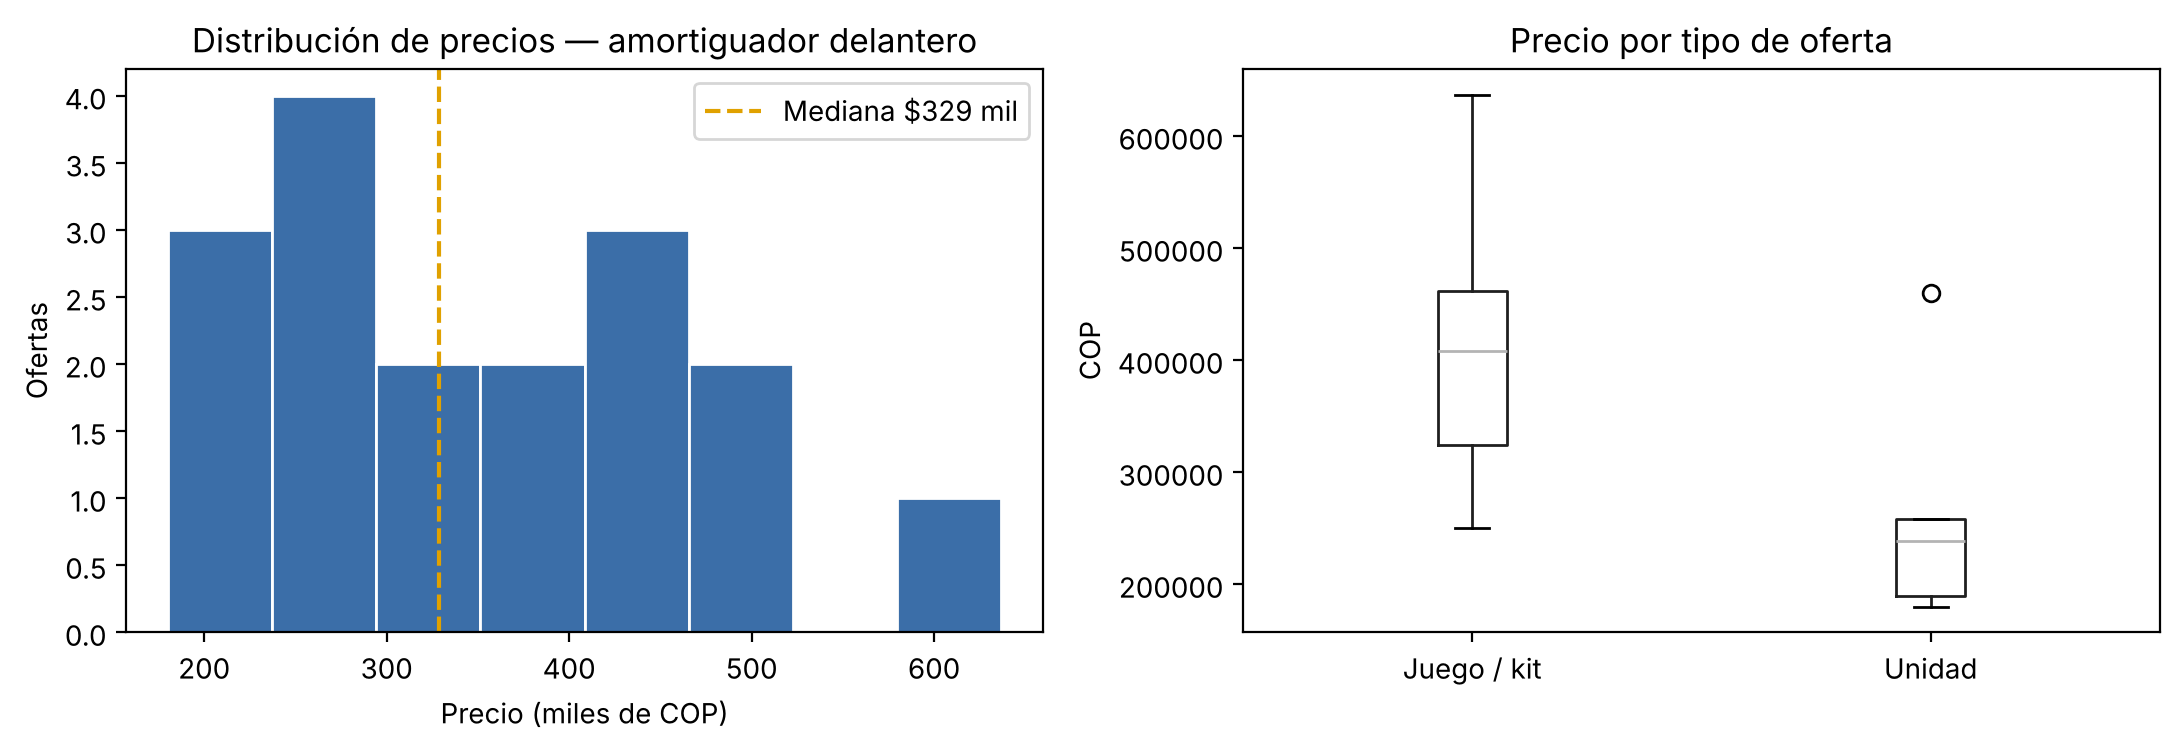

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(limpio["precio_cop"] / 1000, bins=8, color="#3b6ea8", edgecolor="white")
ax[0].axvline(mediana / 1000, color="#e0a100", ls="--", label=f"Mediana ${mediana/1000:,.0f} mil")
ax[0].set_xlabel("Precio (miles de COP)"); ax[0].set_ylabel("Ofertas"); ax[0].legend()
ax[0].set_title("Distribución de precios — amortiguador delantero")
limpio.boxplot(column="precio_cop", by="tipo", ax=ax[1], grid=False)
ax[1].set_title("Precio por tipo de oferta"); ax[1].set_xlabel(""); ax[1].set_ylabel("COP")
plt.suptitle(""); plt.tight_layout(); plt.show()

## 5. Carga
Se guarda el resultado limpio y un historial con fecha (pieza → historial), igual que `precios.json` en la app. La recolección se repite cada 12 h.

In [8]:
limpio.drop(columns=["valido", "motivo_descarte"]).to_csv("precios_limpios.csv", index=False)
historial = {}
if os.path.exists("precios.json"):
    historial = json.load(open("precios.json", encoding="utf-8"))
historial.setdefault(CONSULTA, []).append({
    "fecha": str(crudo["fecha"].iloc[0]), "ofertas": n, "mediana": mediana,
    "min": precios[0], "max": precios[-1], "q1": q1, "q3": q3})
json.dump(historial, open("precios.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
historial

{'amortiguador delantero': [{'fecha': '2026-11-26',
   'ofertas': 17,
   'mediana': 328900,
   'min': 180000,
   'max': 636900,
   'q1': 257900.0,
   'q3': 442900.0}]}

## 6. Señal del acelerómetro (ESP32 + MPU6050)
Entrada: el CSV que genera `scripts/descargar_esp32.py` (`t_s, ax_g, ay_g, az_g, total_g, choque, bache, boton`, 100 Hz).

Cadena: magnitud − 1 g (quitar gravedad) → filtro pasa-altos (pendientes) → ventanas de 1 s con 50 % de traslape → pico, RMS, desviación, pico a pico y factor de cresta → reglas de umbral:
1. pico ≥ umbral (sensibilidad media: 6 m/s²),
2. factor de cresta (pico/RMS) ≥ 3,2,
3. pico ≥ 4 × RMS de fondo (promedio móvil, α = 0,1).

(La condición de velocidad > 10 km/h la aplica la app con el GPS.)

In [9]:
G = 9.81
SENAL = "datos_esp32/sesion.csv"   # cambiar por la sesión descargada del ESP32

def procesar(ruta, fs=100, umbral=6.0, cresta=3.2, k_fondo=4.0, alfa=0.1):
    s = pd.read_csv(ruta)
    a = (s["total_g"].values - 1.0) * G                    # m/s² sin gravedad
    lento = pd.Series(a).ewm(alpha=1 / fs).mean().values   # pasa-altos: se resta la tendencia lenta
    a = a - lento
    w, paso = fs, fs // 2                                  # 1 s, 50 % de traslape
    filas, fondo = [], None
    for i in range(0, len(a) - w + 1, paso):
        v = a[i:i + w]
        pico, rms = np.max(np.abs(v)), np.sqrt(np.mean(v ** 2))
        fondo = rms if fondo is None else fondo
        es_hueco = pico >= umbral and pico / max(rms, 1e-6) >= cresta and pico >= k_fondo * fondo
        if not es_hueco:
            fondo = alfa * rms + (1 - alfa) * fondo
        filas.append(dict(t_s=i / fs, pico=pico, rms=rms, std=np.std(v), p2p=np.ptp(v),
                          cresta=pico / max(rms, 1e-6), hueco=es_hueco,
                          marca_esp32=int(s["bache"].values[i:i + w].max()),
                          marca_mano=int(s["boton"].values[i:i + w].max())))
    return s, a, pd.DataFrame(filas)

if os.path.exists(SENAL):
    s, a, ventanas = procesar(SENAL)
    print(len(s), "lecturas ·", len(ventanas), "ventanas ·", int(ventanas["hueco"].sum()), "ventanas con hueco")
    plt.figure(figsize=(11, 3))
    plt.plot(s["t_s"], a, lw=0.6)
    for t in ventanas.loc[ventanas["hueco"], "t_s"]:
        plt.axvspan(t, t + 1, color="red", alpha=0.2)
    plt.xlabel("t (s)"); plt.ylabel("|a| − g (m/s²)"); plt.title("Señal del MPU6050 y ventanas clasificadas como hueco")
    plt.show()
    display(ventanas[ventanas["hueco"]])
else:
    print("Coloca aquí la sesión descargada del ESP32:", SENAL)

Coloca aquí la sesión descargada del ESP32: datos_esp32/sesion.csv
